In [ ]:
import ee
import geemap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio
import os
import json

from google.colab import drive

In [ ]:
ee.Authenticate()

In [ ]:
ee.Initialize(project="deforestation-513610")

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/DeforestationProject"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
RAW_DIR = os.path.join(DATA_DIR, "raw")
PROCESSED_DIR = os.path.join(DATA_DIR, "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULT_DIR = os.path.join(PROJECT_DIR, "results")

for folder in [
    RAW_DIR,
    PROCESSED_DIR,
    MODEL_DIR,
    RESULT_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
# Pune
pune_aoi = ee.Geometry.Rectangle([
    73.55, 18.35,
    73.58, 18.38
])

# Satara
satara_aoi = ee.Geometry.Rectangle([
    73.75, 17.70,
    73.78, 17.73
])

# Sindhudurg
sindhudurg_aoi = ee.Geometry.Rectangle([
    73.65, 15.95,
    73.68, 15.98
])

# Store all AOIs in one dictionary
study_aois = {
    "Pune": pune_aoi,
    "Satara": satara_aoi,
    "Sindhudurg": sindhudurg_aoi
}

print("Study areas created:")
for name in study_aois:
    print(name)

Study areas created:
Pune
Satara
Sindhudurg


In [ ]:
Map = geemap.Map(basemap="Esri.WorldImagery")

for name, region in study_aois.items():
    Map.addLayer(
        region,
        {"color": "red"},
        name
    )

Map.centerObject(
    ee.FeatureCollection([
        ee.Feature(region)
        for region in study_aois.values()
    ]),
    7
)

Map

Map(center=[17.342853099034475, 73.66524449783005], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
)

print("ESA WorldCover 2021 loaded successfully")

ESA WorldCover 2021 loaded successfully


In [ ]:
# Convert original ESA class codes into display indices
class_values = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]

display_image = worldcover.remap(
    class_values,
    list(range(len(class_values)))
)

palette = [
    "006400",  # Tree cover
    "ffbb22",  # Shrubland
    "ffff4c",  # Grassland
    "f096ff",  # Cropland
    "fa0000",  # Built-up
    "b4b4b4",  # Bare / sparse vegetation
    "f0f0f0",  # Snow and ice
    "0064c8",  # Water
    "0096a0",  # Wetland
    "00cf75",  # Mangroves
    "fae6a0"   # Moss and lichen
]

Map = geemap.Map(basemap="Esri.WorldImagery")

Map.addLayer(
    display_image,
    {
        "min": 0,
        "max": 10,
        "palette": palette
    },
    "ESA WorldCover 2021"
)

for name, region in study_aois.items():
    Map.addLayer(region, {"color": "red"}, name)

Map.centerObject(
    ee.FeatureCollection([
        ee.Feature(region)
        for region in study_aois.values()
    ]),
    7
)

Map

Map(center=[17.342853099034503, 73.66524449783414], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
def get_sentinel_collection(region, year):

    start_date = f"{year}-01-01"
    end_date = f"{year}-04-01"

    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(region)
        .filterDate(start_date, end_date)
        .filter(
            ee.Filter.lt(
                "CLOUDY_PIXEL_PERCENTAGE",
                40
            )
        )
    )

    return collection

In [ ]:
def remove_clouds(image):

    scl = image.select("SCL")

    # Remove no-data, defective pixels, shadows,
    # medium/high probability clouds, cirrus and snow
    cloud_mask = (
        scl.neq(0)
        .And(scl.neq(1))
        .And(scl.neq(3))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    clean_image = (
        image.updateMask(cloud_mask)
        .select(["B2", "B3", "B4", "B8"])
        .multiply(0.0001)
        .toFloat()
    )

    return clean_image

In [ ]:
def create_composite(region, year):

    collection = get_sentinel_collection(
        region,
        year
    )

    print(
        f"{year}: Satellite images found =",
        collection.size().getInfo()
    )

    clean_collection = collection.map(
        remove_clouds
    )

    composite = (
        clean_collection
        .median()
        .clip(region)
        .toFloat()
    )

    return composite

In [ ]:
composites_2021 = {}
composites_2024 = {}

for name, region in study_aois.items():

    print("\nProcessing:", name)

    composites_2021[name] = create_composite(
        region,
        2021
    )

    composites_2024[name] = create_composite(
        region,
        2024
    )

print("\nAll composites created!")


Processing: Pune
2021: Satellite images found = 16
2024: Satellite images found = 15

Processing: Satara
2021: Satellite images found = 15
2024: Satellite images found = 17

Processing: Sindhudurg
2021: Satellite images found = 14
2024: Satellite images found = 17

All composites created!


In [ ]:
district = "Pune"

Map = geemap.Map(basemap="Esri.WorldImagery")

Map.centerObject(
    study_aois[district],
    12
)

Map.addLayer(
    composites_2021[district],
    {
        "bands": ["B4", "B3", "B2"],
        "min": 0,
        "max": 0.3
    },
    "Pune Sentinel-2 2021"
)

Map.addLayer(
    composites_2024[district],
    {
        "bands": ["B4", "B3", "B2"],
        "min": 0,
        "max": 0.3
    },
    "Pune Sentinel-2 2024"
)

Map

Map(center=[18.365000152577448, 73.56500000000297], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
def create_forest_mask(region):

    forest_mask = (
        worldcover
        .eq(10)
        .rename("forest")
        .clip(region)
        .toFloat()
    )

    return forest_mask

In [ ]:
training_images = {}

for name, region in study_aois.items():

    forest_mask = create_forest_mask(region)

    training_image = (
        composites_2021[name]
        .addBands(forest_mask)
        .toFloat()
    )

    training_images[name] = training_image

    print(name, "training image created")

Pune training image created
Satara training image created
Sindhudurg training image created


In [ ]:
export_tasks = []

for name, region in study_aois.items():

    # Export 2021 imagery + reference label
    task_2021 = ee.batch.Export.image.toDrive(
        image=training_images[name],
        description=f"{name}_2021_training",
        folder="DeforestationProject",
        fileNamePrefix=f"{name}_2021_training",
        region=region,
        scale=10,
        maxPixels=1e10,
        fileFormat="GeoTIFF"
    )

    # Export 2024 imagery without labels
    task_2024 = ee.batch.Export.image.toDrive(
        image=composites_2024[name],
        description=f"{name}_2024_comparison",
        folder="DeforestationProject",
        fileNamePrefix=f"{name}_2024_comparison",
        region=region,
        scale=10,
        maxPixels=1e10,
        fileFormat="GeoTIFF"
    )

    task_2021.start()
    task_2024.start()

    export_tasks.extend([task_2021, task_2024])

    print(f"Export started for {name}")

Export started for Pune
Export started for Satara
Export started for Sindhudurg


In [ ]:
for task in export_tasks:

    status = task.status()

    print(
        status["description"],
        ":",
        status["state"]
    )

Pune_2021_training : READY
Pune_2024_comparison : READY
Satara_2021_training : READY
Satara_2024_comparison : READY
Sindhudurg_2021_training : READY
Sindhudurg_2024_comparison : READY


In [ ]:
for task in export_tasks:

    status = task.status()

    if status["state"] == "FAILED":

        print("FAILED:", status["description"])
        print("Error:", status.get("error_message"))

In [ ]:
import glob

DRIVE_DATA_DIR = "/content/drive/MyDrive/DeforestationProject"

tif_files = glob.glob(
    os.path.join(DRIVE_DATA_DIR, "*.tif")
)

print("Total GeoTIFF files:", len(tif_files))

for file in sorted(tif_files):
    print(os.path.basename(file))

Total GeoTIFF files: 6
Pune_2021_training.tif
Pune_2024_comparison.tif
Satara_2021_training.tif
Satara_2024_comparison.tif
Sindhudurg_2021_training.tif
Sindhudurg_2024_comparison.tif


In [ ]:
pune_2021_path = os.path.join(
    DRIVE_DATA_DIR,
    "Pune_2021_training.tif"
)

with rasterio.open(pune_2021_path) as src:

    pune_2021 = src.read(masked=True)

    print("Number of bands:", src.count)
    print("Width:", src.width)
    print("Height:", src.height)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Data types:", src.dtypes)
    bounds=src.bounds
    print("Bounds:", src.bounds)

Number of bands: 5
Width: 335
Height: 335
CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Data types: ('float32', 'float32', 'float32', 'float32', 'float32')
Bounds: BoundingBox(left=73.54992321339947, bottom=18.349976140237878, right=73.58001677541748, top=18.38006970225588)


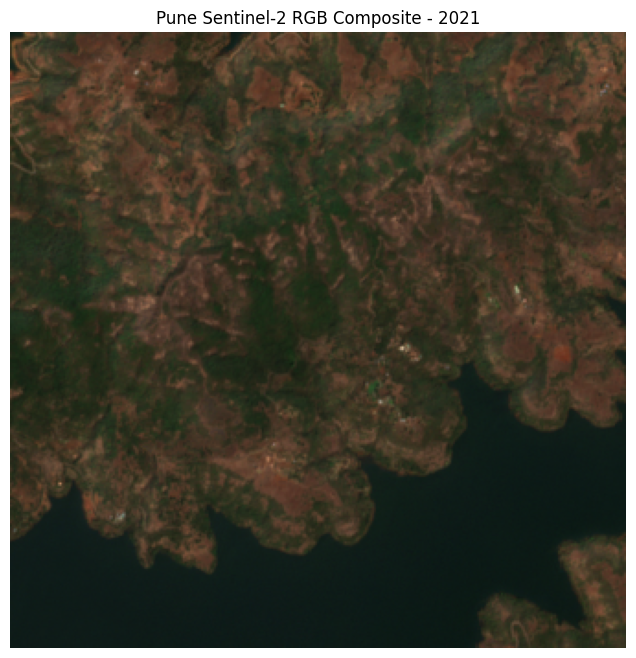

In [ ]:
# Convert band-first format to image format
# (bands, height, width) -> (height, width, bands)

pune_rgb = np.stack([
    pune_2021[2].filled(0),  # B4 - Red
    pune_2021[1].filled(0),  # B3 - Green
    pune_2021[0].filled(0)   # B2 - Blue
], axis=-1)

plt.figure(figsize=(10, 8))

plt.imshow(
    np.clip(pune_rgb / 0.3, 0, 1)
)

plt.title("Pune Sentinel-2 RGB Composite - 2021")
plt.axis("off")
plt.show()

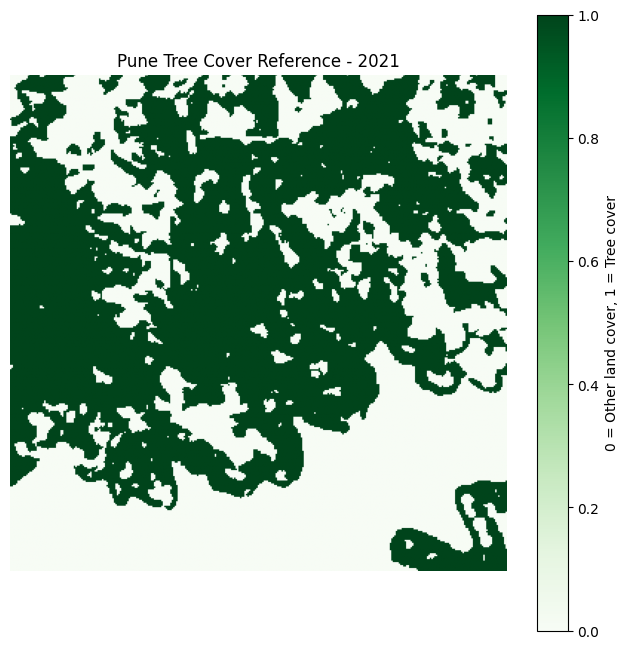

In [ ]:
forest_label = pune_2021[4].filled(0)

plt.figure(figsize=(8, 8))

plt.imshow(
    forest_label,
    cmap="Greens",
    vmin=0,
    vmax=1
)

plt.title("Pune Tree Cover Reference - 2021")
plt.colorbar(label="0 = Other land cover, 1 = Tree cover")
plt.axis("off")
plt.show()

In [ ]:
import os
import numpy as np
import rasterio

DATA_DIR = "/content/drive/MyDrive/DeforestationProject"

districts = ["Pune", "Satara", "Sindhudurg"]

training_paths = {
    district: os.path.join(
        DATA_DIR,
        f"{district}_2021_training.tif"
    )
    for district in districts
}

comparison_paths = {
    district: os.path.join(
        DATA_DIR,
        f"{district}_2024_comparison.tif"
    )
    for district in districts
}

# Check whether all six files exist

for district in districts:

    print(f"\n{district}")

    print(
        "2021:",
        os.path.exists(training_paths[district])
    )

    print(
        "2024:",
        os.path.exists(comparison_paths[district])
    )


Pune
2021: True
2024: True

Satara
2021: True
2024: True

Sindhudurg
2021: True
2024: True


In [ ]:
all_paths = {
    **{
        f"{district}_2021": path
        for district, path in training_paths.items()
    },
    **{
        f"{district}_2024": path
        for district, path in comparison_paths.items()
    }
}

for name, path in all_paths.items():

    with rasterio.open(path) as src:

        print("\n", name)
        print("-" * 45)

        print("Bands:", src.count)
        print("Width:", src.width)
        print("Height:", src.height)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Data types:", src.dtypes)
        print("NoData:", src.nodata)
        print("Bounds:", src.bounds)


 Pune_2021
---------------------------------------------
Bands: 5
Width: 335
Height: 335
CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Data types: ('float32', 'float32', 'float32', 'float32', 'float32')
NoData: None
Bounds: BoundingBox(left=73.54992321339947, bottom=18.349976140237878, right=73.58001677541748, top=18.38006970225588)

 Satara_2021
---------------------------------------------
Bands: 5
Width: 335
Height: 335
CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Data types: ('float32', 'float32', 'float32', 'float32', 'float32')
NoData: None
Bounds: BoundingBox(left=73.74997802717289, bottom=17.699955200648994, right=73.7800715891909, top=17.730048762666996)

 Sindhudurg_2021
---------------------------------------------
Bands: 5
Width: 335
Height: 335
CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Data types: ('float32', 'float32', 'float32', 'float32', 'float32')
NoData: None
Bounds: BoundingBox

In [ ]:
def load_training_raster(path):

    with rasterio.open(path) as src:

        # Read all five bands
        raster = src.read(masked=True)

        # First four bands are satellite imagery
        image = np.stack([
            raster[0].filled(0),
            raster[1].filled(0),
            raster[2].filled(0),
            raster[3].filled(0)
        ], axis=-1).astype(np.float32)

        # Fifth band is the reference label
        label = raster[4].filled(0).astype(np.float32)

        # Check which pixels are valid in every band
        raster_mask = np.ma.getmaskarray(raster)

        valid_mask = (
            ~raster_mask[:4].any(axis=0)
            &
            ~raster_mask[4]
            &
            np.isfinite(image).all(axis=-1)
            &
            np.isfinite(label)
        )

        # Keep labels strictly binary
        label = (label >= 0.5).astype(np.float32)

        # Save metadata for future geospatial outputs
        metadata = src.profile.copy()

    return image, label, valid_mask, metadata

In [ ]:
training_data = {}

for district in districts:

    print("\nLoading:", district)

    image, label, valid_mask, metadata = (
        load_training_raster(
            training_paths[district]
        )
    )

    training_data[district] = {
        "image": image,
        "label": label,
        "valid_mask": valid_mask,
        "metadata": metadata
    }

    print("Image shape:", image.shape)
    print("Label shape:", label.shape)
    print("Valid pixels:", valid_mask.sum())
    print("Total pixels:", valid_mask.size)


Loading: Pune
Image shape: (335, 335, 4)
Label shape: (335, 335)
Valid pixels: 112225
Total pixels: 112225

Loading: Satara
Image shape: (335, 335, 4)
Label shape: (335, 335)
Valid pixels: 112225
Total pixels: 112225

Loading: Sindhudurg
Image shape: (335, 335, 4)
Label shape: (335, 335)
Valid pixels: 112224
Total pixels: 112225


In [ ]:
training_data["Pune"]["image"]
training_data["Satara"]["label"]
training_data["Sindhudurg"]["valid_mask"]

array([[ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       ...,
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True, False]], shape=(335, 335))

In [ ]:
def load_comparison_raster(path):

    with rasterio.open(path) as src:

        raster = src.read(masked=True)

        image = np.stack([
            raster[0].filled(0),
            raster[1].filled(0),
            raster[2].filled(0),
            raster[3].filled(0)
        ], axis=-1).astype(np.float32)

        raster_mask = np.ma.getmaskarray(raster)

        valid_mask = (
            ~raster_mask.any(axis=0)
            &
            np.isfinite(image).all(axis=-1)
        )

        metadata = src.profile.copy()

    return image, valid_mask, metadata

In [ ]:
comparison_data = {}

for district in districts:

    print("\nLoading 2024:", district)

    image, valid_mask, metadata = (
        load_comparison_raster(
            comparison_paths[district]
        )
    )

    comparison_data[district] = {
        "image": image,
        "valid_mask": valid_mask,
        "metadata": metadata
    }

    print("Image shape:", image.shape)
    print("Valid pixels:", valid_mask.sum())


Loading 2024: Pune
Image shape: (335, 335, 4)
Valid pixels: 112225

Loading 2024: Satara
Image shape: (335, 335, 4)
Valid pixels: 112225

Loading 2024: Sindhudurg
Image shape: (335, 335, 4)
Valid pixels: 112224


In [ ]:
for district in districts:

    label = training_data[district]["label"]
    valid = training_data[district]["valid_mask"]

    valid_labels = label[valid]

    tree_pixels = np.sum(valid_labels == 1)
    non_tree_pixels = np.sum(valid_labels == 0)

    total = len(valid_labels)

    tree_percentage = (
        tree_pixels / total * 100
        if total > 0 else 0
    )

    non_tree_percentage = (
        non_tree_pixels / total * 100
        if total > 0 else 0
    )

    print("\n", district)
    print("-" * 40)

    print("Tree pixels:", tree_pixels)
    print("Non-tree pixels:", non_tree_pixels)

    print("Tree cover:", round(tree_percentage, 2), "%")
    print("Non-tree cover:", round(non_tree_percentage, 2), "%")


 Pune
----------------------------------------
Tree pixels: 60882
Non-tree pixels: 51343
Tree cover: 54.25 %
Non-tree cover: 45.75 %

 Satara
----------------------------------------
Tree pixels: 48633
Non-tree pixels: 63592
Tree cover: 43.34 %
Non-tree cover: 56.66 %

 Sindhudurg
----------------------------------------
Tree pixels: 91388
Non-tree pixels: 20836
Tree cover: 81.43 %
Non-tree cover: 18.57 %


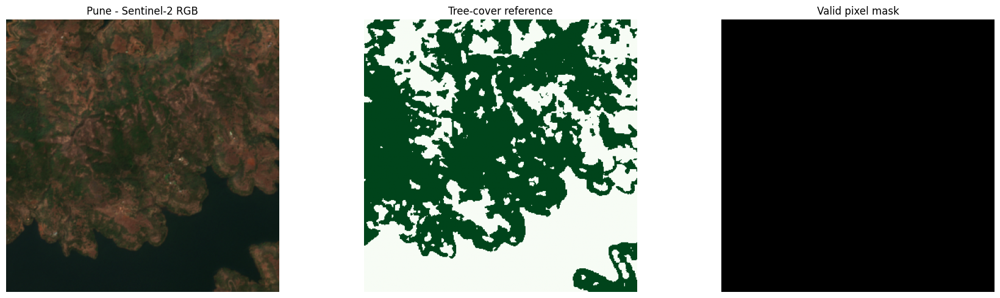

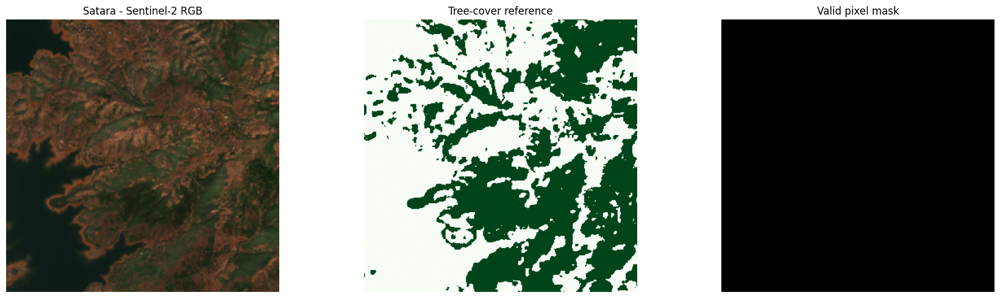

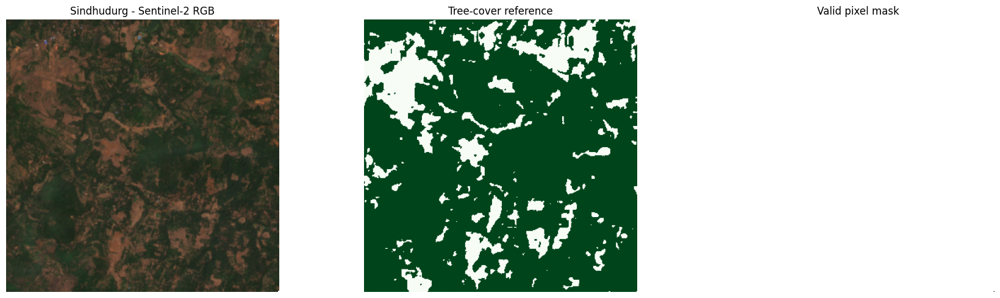

In [ ]:
for district in districts:

    image = training_data[district]["image"]
    label = training_data[district]["label"]
    valid = training_data[district]["valid_mask"]

    # RGB: B4, B3, B2
    rgb = image[:, :, [2, 1, 0]]

    # Display reflectance
    rgb_display = np.clip(rgb / 0.3, 0, 1)

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 5)
    )

    axes[0].imshow(rgb_display)
    axes[0].set_title(f"{district} - Sentinel-2 RGB")

    axes[1].imshow(label, cmap="Greens", vmin=0, vmax=1)
    axes[1].set_title("Tree-cover reference")

    axes[2].imshow(valid, cmap="gray")
    axes[2].set_title("Valid pixel mask")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
PATCH_SIZE = 128
STRIDE = 64

MIN_VALID_FRACTION = 0.95

print("Patch size:", PATCH_SIZE)
print("Stride:", STRIDE)
print("Minimum valid pixels:", MIN_VALID_FRACTION * 100, "%")

Patch size: 128
Stride: 64
Minimum valid pixels: 95.0 %


In [ ]:
# Collect valid pixel values from all training districts

all_valid_pixels = []

for district in districts:

    image = training_data[district]["image"]
    valid = training_data[district]["valid_mask"]

    pixels = image[valid]

    all_valid_pixels.append(pixels)

all_valid_pixels = np.concatenate(
    all_valid_pixels,
    axis=0
)

print("Total valid pixels:", len(all_valid_pixels))
print("Band values shape:", all_valid_pixels.shape)

Total valid pixels: 336674
Band values shape: (336674, 4)


In [ ]:
band_limits = {}

for band in range(4):

    p2 = np.percentile(
        all_valid_pixels[:, band],
        2
    )

    p98 = np.percentile(
        all_valid_pixels[:, band],
        98
    )

    band_limits[band] = (p2, p98)

    print(
        f"Band {band + 1}:",
        "P2 =", round(float(p2), 5),
        "P98 =", round(float(p98), 5)
    )

Band 1: P2 = 0.0251 P98 = 0.0674
Band 2: P2 = 0.0307 P98 = 0.0938
Band 3: P2 = 0.0145 P98 = 0.136
Band 4: P2 = 0.0063 P98 = 0.3109


In [ ]:
def normalize_image(image, valid_mask, band_limits):

    normalized = np.zeros(
        image.shape,
        dtype=np.float32
    )

    for band in range(4):

        p2, p98 = band_limits[band]

        normalized[:, :, band] = np.clip(
            (image[:, :, band] - p2) /
            (p98 - p2 + 1e-6),
            0,
            1
        )

    # Invalid pixels are set to zero
    normalized[~valid_mask] = 0

    return normalized

In [ ]:
normalized_training_data = {}
normalized_comparison_data = {}

for district in districts:

    # 2021 training imagery
    image_2021 = training_data[district]["image"]
    valid_2021 = training_data[district]["valid_mask"]

    normalized_2021 = normalize_image(
        image_2021,
        valid_2021,
        band_limits
    )

    normalized_training_data[district] = normalized_2021

    # 2024 comparison imagery
    image_2024 = comparison_data[district]["image"]
    valid_2024 = comparison_data[district]["valid_mask"]

    normalized_2024 = normalize_image(
        image_2024,
        valid_2024,
        band_limits
    )

    normalized_comparison_data[district] = normalized_2024

    print(district, "normalisation completed")

Pune normalisation completed
Satara normalisation completed
Sindhudurg normalisation completed


In [ ]:
def create_patches(image, label, valid_mask, district):

    image_patches = []
    label_patches = []
    valid_patches = []
    patch_locations = []

    height, width = label.shape

    for row in range(
        0,
        height - PATCH_SIZE + 1,
        STRIDE
    ):

        for col in range(
            0,
            width - PATCH_SIZE + 1,
            STRIDE
        ):

            # Extract satellite image patch
            image_patch = image[
                row:row + PATCH_SIZE,
                col:col + PATCH_SIZE,
                :
            ]

            # Extract reference label patch
            label_patch = label[
                row:row + PATCH_SIZE,
                col:col + PATCH_SIZE
            ]

            # Extract validity patch
            valid_patch = valid_mask[
                row:row + PATCH_SIZE,
                col:col + PATCH_SIZE
            ]

            # Skip patches with too many invalid pixels
            if valid_patch.mean() < MIN_VALID_FRACTION:
                continue

            image_patches.append(image_patch)

            label_patches.append(
                label_patch[..., np.newaxis]
            )

            valid_patches.append(
                valid_patch[..., np.newaxis]
            )

            patch_locations.append({
                "district": district,
                "row": row,
                "col": col
            })

    return (
        np.asarray(image_patches, dtype=np.float32),
        np.asarray(label_patches, dtype=np.float32),
        np.asarray(valid_patches, dtype=bool),
        patch_locations
    )

In [ ]:
district_patches = {}

for district in districts:

    print("\nExtracting patches:", district)

    X, Y, V, locations = create_patches(
        normalized_training_data[district],
        training_data[district]["label"],
        training_data[district]["valid_mask"],
        district
    )

    district_patches[district] = {
        "X": X,
        "Y": Y,
        "V": V,
        "locations": locations
    }

    print("Image patches:", X.shape)
    print("Label patches:", Y.shape)
    print("Validity patches:", V.shape)
    print("Number of patches:", len(locations))


Extracting patches: Pune
Image patches: (16, 128, 128, 4)
Label patches: (16, 128, 128, 1)
Validity patches: (16, 128, 128, 1)
Number of patches: 16

Extracting patches: Satara
Image patches: (16, 128, 128, 4)
Label patches: (16, 128, 128, 1)
Validity patches: (16, 128, 128, 1)
Number of patches: 16

Extracting patches: Sindhudurg
Image patches: (16, 128, 128, 4)
Label patches: (16, 128, 128, 1)
Validity patches: (16, 128, 128, 1)
Number of patches: 16


In [ ]:
X_list = []
Y_list = []
V_list = []
all_patch_locations = []

for district in districts:

    data = district_patches[district]

    X_list.append(data["X"])
    Y_list.append(data["Y"])
    V_list.append(data["V"])

    all_patch_locations.extend(
        data["locations"]
    )

X_all = np.concatenate(X_list, axis=0)
Y_all = np.concatenate(Y_list, axis=0)
V_all = np.concatenate(V_list, axis=0)

print("Combined dataset")
print("-" * 40)

print("X_all:", X_all.shape)
print("Y_all:", Y_all.shape)
print("V_all:", V_all.shape)

print("Total patches:", len(X_all))
print("Location records:", len(all_patch_locations))

Combined dataset
----------------------------------------
X_all: (48, 128, 128, 4)
Y_all: (48, 128, 128, 1)
V_all: (48, 128, 128, 1)
Total patches: 48
Location records: 48


In [ ]:
valid_labels = Y_all[V_all]

tree_pixels = np.sum(valid_labels == 1)
non_tree_pixels = np.sum(valid_labels == 0)

total_pixels = tree_pixels + non_tree_pixels

print("Tree pixels:", tree_pixels)
print("Non-tree pixels:", non_tree_pixels)

print(
    "Tree percentage:",
    round(tree_pixels / total_pixels * 100, 2)
)

print(
    "Non-tree percentage:",
    round(non_tree_pixels / total_pixels * 100, 2)
)

Tree pixels: 498163
Non-tree pixels: 288269
Tree percentage: 63.34
Non-tree percentage: 36.66


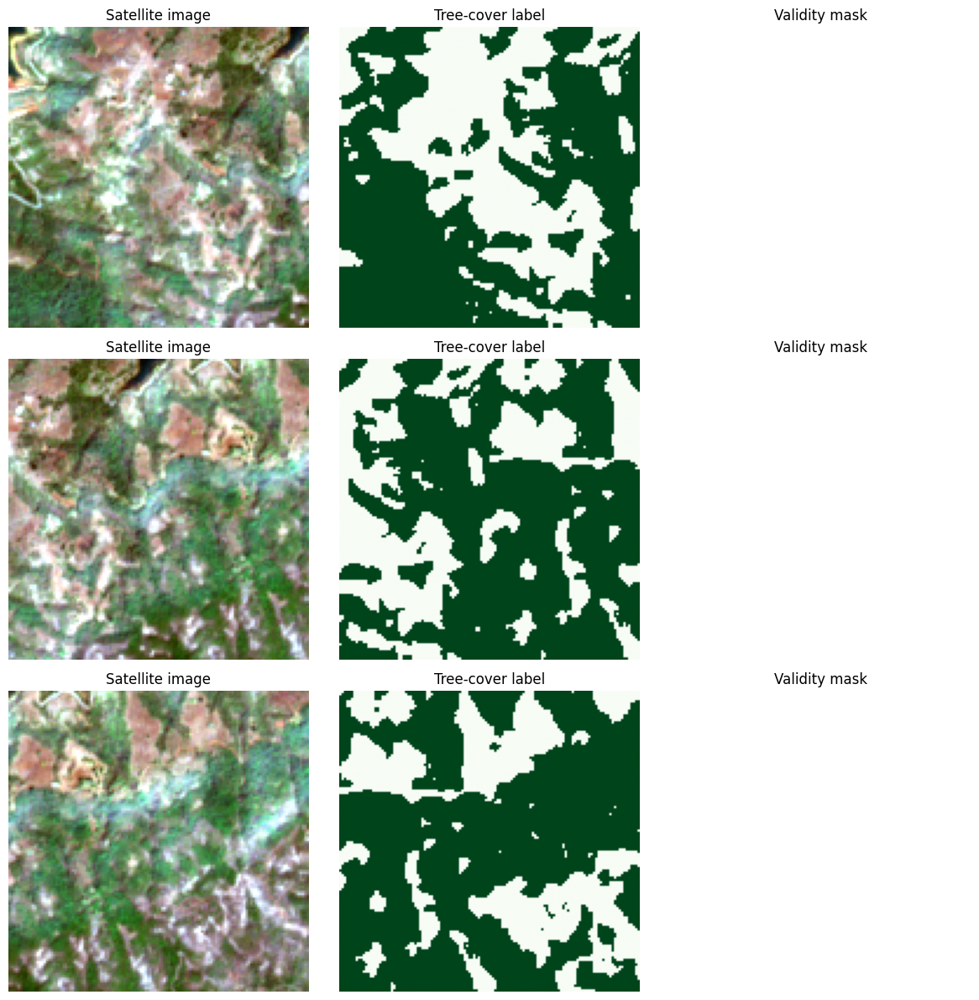

In [ ]:
fig, axes = plt.subplots(
    3, 3,
    figsize=(12, 12)
)

for i in range(3):

    image_patch = X_all[i]

    rgb = image_patch[:, :, [2, 1, 0]]

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title("Satellite image")

    axes[i, 1].imshow(
        Y_all[i, :, :, 0],
        cmap="Greens",
        vmin=0,
        vmax=1
    )
    axes[i, 1].set_title("Tree-cover label")

    axes[i, 2].imshow(
        V_all[i, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i, 2].set_title("Validity mask")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
TRAIN_DISTRICTS = ["Pune", "Satara"]
VAL_DISTRICTS = ["Sindhudurg"]

print("Training districts:", TRAIN_DISTRICTS)
print("Validation districts:", VAL_DISTRICTS)

Training districts: ['Pune', 'Satara']
Validation districts: ['Sindhudurg']


In [ ]:
# Concatenate patches across training districts
X_train_raw = np.concatenate(
    [district_patches[d]["X"] for d in TRAIN_DISTRICTS],
    axis=0
)
Y_train_raw = np.concatenate(
    [district_patches[d]["Y"] for d in TRAIN_DISTRICTS],
    axis=0
)
V_train_raw = np.concatenate(
    [district_patches[d]["V"] for d in TRAIN_DISTRICTS],
    axis=0
)

# -------------------------------------------------------------------------
# DATA AUGMENTATION (D4 Symmetry Group: 8-Fold Spatial Invariance Expansion)
# Solves the small dataset bottleneck (expands 32 raw patches to 256 patches)
# -------------------------------------------------------------------------
aug_X = [X_train_raw]
aug_Y = [Y_train_raw]
aug_V = [V_train_raw]

# 90, 180, 270 degree rotations
for k in [1, 2, 3]:
    aug_X.append(np.rot90(X_train_raw, k, axes=(1, 2)))
    aug_Y.append(np.rot90(Y_train_raw, k, axes=(1, 2)))
    aug_V.append(np.rot90(V_train_raw, k, axes=(1, 2)))

# Horizontal and vertical flips
aug_X.append(np.flip(X_train_raw, axis=2))
aug_Y.append(np.flip(Y_train_raw, axis=2))
aug_V.append(np.flip(V_train_raw, axis=2))

aug_X.append(np.flip(X_train_raw, axis=1))
aug_Y.append(np.flip(Y_train_raw, axis=1))
aug_V.append(np.flip(V_train_raw, axis=1))

# Diagonal and anti-diagonal transpositions
aug_X.append(np.swapaxes(X_train_raw, 1, 2))
aug_Y.append(np.swapaxes(Y_train_raw, 1, 2))
aug_V.append(np.swapaxes(V_train_raw, 1, 2))

aug_X.append(np.swapaxes(np.rot90(X_train_raw, 2, axes=(1, 2)), 1, 2))
aug_Y.append(np.swapaxes(np.rot90(Y_train_raw, 2, axes=(1, 2)), 1, 2))
aug_V.append(np.swapaxes(np.rot90(V_train_raw, 2, axes=(1, 2)), 1, 2))

X_train = np.concatenate(aug_X, axis=0)
Y_train = np.concatenate(aug_Y, axis=0)
V_train = np.concatenate(aug_V, axis=0)

# Shuffle augmented patches synchronously
rng = np.random.default_rng(42)
perm = rng.permutation(len(X_train))
X_train, Y_train, V_train = X_train[perm], Y_train[perm], V_train[perm]

print(f"Raw patches: {len(X_train_raw)} -> Augmented Training Patches: {len(X_train)} (8x Expansion)")
print("Training image shape:", X_train.shape)
print("Training label shape:", Y_train.shape)
print("Training validity shape:", V_train.shape)


Training image shape: (32, 128, 128, 4)
Training label shape: (32, 128, 128, 1)
Training validity shape: (32, 128, 128, 1)


In [ ]:
X_val = np.concatenate(
    [
        district_patches[d]["X"]
        for d in VAL_DISTRICTS
    ],
    axis=0
)

Y_val = np.concatenate(
    [
        district_patches[d]["Y"]
        for d in VAL_DISTRICTS
    ],
    axis=0
)

V_val = np.concatenate(
    [
        district_patches[d]["V"]
        for d in VAL_DISTRICTS
    ],
    axis=0
)

print("Validation image shape:", X_val.shape)
print("Validation label shape:", Y_val.shape)
print("Validation validity shape:", V_val.shape)

Validation image shape: (16, 128, 128, 4)
Validation label shape: (16, 128, 128, 1)
Validation validity shape: (16, 128, 128, 1)


In [ ]:
print("TRAINING DATASET")
print("-" * 40)
print("Number of patches:", len(X_train))
print("Image shape:", X_train.shape)
print("Labels shape:", Y_train.shape)

print("\nVALIDATION DATASET")
print("-" * 40)
print("Number of patches:", len(X_val))
print("Image shape:", X_val.shape)
print("Labels shape:", Y_val.shape)

TRAINING DATASET
----------------------------------------
Number of patches: 32
Image shape: (32, 128, 128, 4)
Labels shape: (32, 128, 128, 1)

VALIDATION DATASET
----------------------------------------
Number of patches: 16
Image shape: (16, 128, 128, 4)
Labels shape: (16, 128, 128, 1)


In [ ]:
def calculate_class_distribution(labels, valid_mask, name):

    valid_labels = labels[valid_mask]

    tree_pixels = np.sum(valid_labels == 1)
    non_tree_pixels = np.sum(valid_labels == 0)

    total = tree_pixels + non_tree_pixels

    print("\n", name)
    print("-" * 40)

    print("Tree pixels:", tree_pixels)
    print("Non-tree pixels:", non_tree_pixels)

    print(
        "Tree percentage:",
        round(tree_pixels / total * 100, 2)
    )

    print(
        "Non-tree percentage:",
        round(non_tree_pixels / total * 100, 2)
    )


calculate_class_distribution(
    Y_train,
    V_train,
    "Training"
)

calculate_class_distribution(
    Y_val,
    V_val,
    "Validation"
)


 Training
----------------------------------------
Tree pixels: 281669
Non-tree pixels: 242619
Tree percentage: 53.72
Non-tree percentage: 46.28

 Validation
----------------------------------------
Tree pixels: 216494
Non-tree pixels: 45650
Tree percentage: 82.59
Non-tree percentage: 17.41


In [ ]:
valid_train_labels = Y_train[V_train]

class_counts = np.bincount(
    valid_train_labels.astype(np.uint8),
    minlength=2
)

total = class_counts.sum()

class_weights = {
    0: total / (2 * class_counts[0]),
    1: total / (2 * class_counts[1])
}

print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class counts: [242619 281669]
Class weights: {0: np.float64(1.0804759726155), 1: np.float64(0.9306810476126234)}


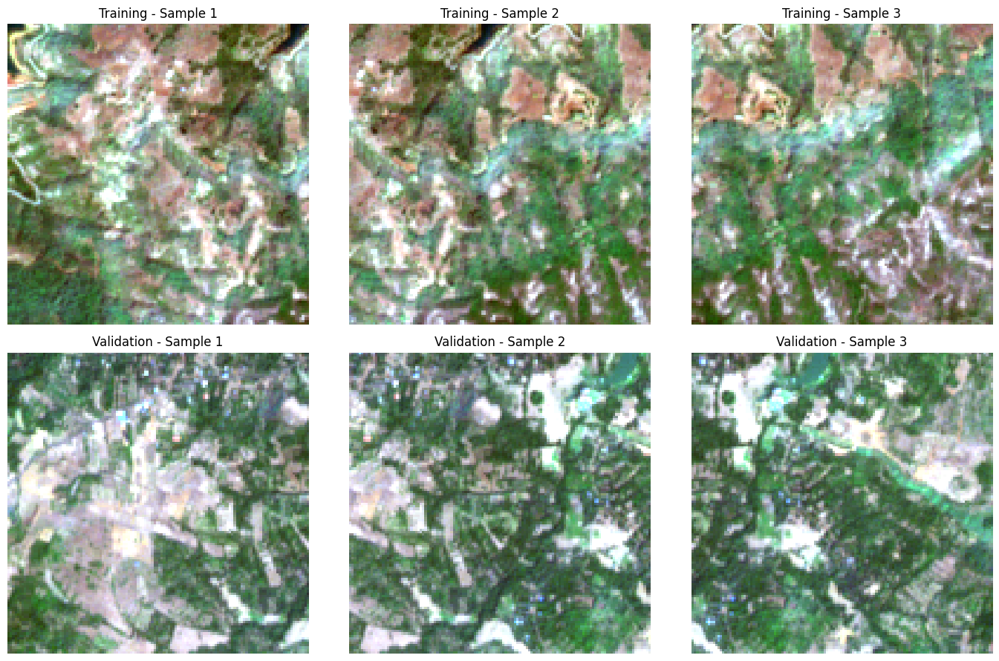

In [ ]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 9)
)

# Training samples
for i in range(3):

    axes[0, i].imshow(
        X_train[i][:, :, [2, 1, 0]]
    )

    axes[0, i].set_title(
        f"Training - Sample {i+1}"
    )

    axes[0, i].axis("off")

# Validation samples
for i in range(3):

    axes[1, i].imshow(
        X_val[i][:, :, [2, 1, 0]]
    )

    axes[1, i].set_title(
        f"Validation - Sample {i+1}"
    )

    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
assert len(X_train) > 0, "Training dataset is empty!"
assert len(X_val) > 0, "Validation dataset is empty!"

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()

assert V_train.any(), "No valid training pixels!"
assert V_val.any(), "No valid validation pixels!"

assert class_counts[0] > 0, "Training has no non-tree pixels!"
assert class_counts[1] > 0, "Training has no tree pixels!"

print("Dataset checks passed!")

Dataset checks passed!


# build the U net model

In [ ]:
import tensorflow as tf

from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
IMAGE_SIZE = 128
INPUT_CHANNELS = 4
OUTPUT_CHANNELS = 1

BATCH_SIZE = 8
EPOCHS = 30

INPUT_SHAPE = (
    IMAGE_SIZE,
    IMAGE_SIZE,
    INPUT_CHANNELS
)

print("Input shape:", INPUT_SHAPE)

Input shape: (128, 128, 4)


In [ ]:
def residual_conv_block(inputs, filters, dropout_rate=0.1):
    """
    Residual Convolution Block:
    Shortcut connection + 2x (Conv2D -> BatchNorm -> ReLU) + Spatial Dropout.
    Preserves fine canopy boundaries, micro-clearings, and eliminates vanishing gradients.
    """
    shortcut = layers.Conv2D(filters, kernel_size=1, padding="same", use_bias=False)(inputs)
    shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Conv2D(filters, kernel_size=3, padding="same", kernel_initializer="he_normal")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    if dropout_rate > 0:
        x = layers.SpatialDropout2D(dropout_rate)(x)

    x = layers.Conv2D(filters, kernel_size=3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)

    x = layers.Add()([shortcut, x])
    x = layers.Activation("relu")(x)
    return x

def aspp_block(inputs, filters):
    """
    Atrous Spatial Pyramid Pooling (ASPP):
    Multi-scale dilated convolutions capture forest features at multiple contextual scales:
    individual tree canopies, narrow logging roads, and continuous deep forest reserves.
    """
    shape = inputs.shape
    b0 = layers.Conv2D(filters, 1, padding="same", use_bias=False)(inputs)
    b0 = layers.BatchNormalization()(b0); b0 = layers.Activation("relu")(b0)

    b1 = layers.Conv2D(filters, 3, dilation_rate=6, padding="same", use_bias=False)(inputs)
    b1 = layers.BatchNormalization()(b1); b1 = layers.Activation("relu")(b1)

    b2 = layers.Conv2D(filters, 3, dilation_rate=12, padding="same", use_bias=False)(inputs)
    b2 = layers.BatchNormalization()(b2); b2 = layers.Activation("relu")(b2)

    b3 = layers.Conv2D(filters, 3, dilation_rate=18, padding="same", use_bias=False)(inputs)
    b3 = layers.BatchNormalization()(b3); b3 = layers.Activation("relu")(b3)

    b4 = layers.GlobalAveragePooling2D(keepdims=True)(inputs)
    b4 = layers.Conv2D(filters, 1, padding="same", use_bias=False)(b4)
    b4 = layers.BatchNormalization()(b4); b4 = layers.Activation("relu")(b4)
    b4 = layers.Resizing(shape[1], shape[2])(b4)

    out = layers.Concatenate()([b0, b1, b2, b3, b4])
    out = layers.Conv2D(filters, 1, padding="same", use_bias=False)(out)
    out = layers.BatchNormalization()(out); out = layers.Activation("relu")(out)
    return layers.Dropout(0.3)(out)

def attention_gate(skip_features, gating_signal, inter_filters):
    """Additive Attention Gate suppressing non-forest background features."""
    theta_x = layers.Conv2D(inter_filters, kernel_size=1, padding="same", use_bias=False)(skip_features)
    phi_g = layers.Conv2D(inter_filters, kernel_size=1, padding="same", use_bias=False)(gating_signal)
    concat = layers.Add()([theta_x, phi_g])
    act = layers.Activation("relu")(concat)
    psi = layers.Conv2D(1, kernel_size=1, padding="same", activation="sigmoid")(act)
    return layers.Multiply()([skip_features, psi])


In [ ]:
def build_attention_res_unet(input_shape=(128, 128, 4), base_filters=32, use_aspp=True):
    """
    Builds an Attention Residual U-Net with ASPP Bottleneck.
    Features:
    - Residual skip connections in encoder & decoder blocks
    - Atrous Spatial Pyramid Pooling (ASPP) at bottleneck
    - Additive Attention Gates on all skip connections
    """
    inputs = layers.Input(shape=input_shape, name="sentinel2_input")

    # Encoder
    c1 = residual_conv_block(inputs, base_filters)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = residual_conv_block(p1, base_filters * 2)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = residual_conv_block(p2, base_filters * 4)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    c4 = residual_conv_block(p3, base_filters * 8)
    p4 = layers.MaxPooling2D((2, 2))(c4)

    # Bottleneck with ASPP multi-scale context
    if use_aspp:
        bottleneck = aspp_block(p4, base_filters * 16)
    else:
        bottleneck = residual_conv_block(p4, base_filters * 16, dropout_rate=0.3)

    # Decoder with Attention Gates
    u1 = layers.Conv2DTranspose(base_filters * 8, kernel_size=2, strides=2, padding="same")(bottleneck)
    ag1 = attention_gate(skip_features=c4, gating_signal=u1, inter_filters=base_filters * 4)
    u1 = layers.Concatenate()([u1, ag1])
    c5 = residual_conv_block(u1, base_filters * 8)

    u2 = layers.Conv2DTranspose(base_filters * 4, kernel_size=2, strides=2, padding="same")(c5)
    ag2 = attention_gate(skip_features=c3, gating_signal=u2, inter_filters=base_filters * 2)
    u2 = layers.Concatenate()([u2, ag2])
    c6 = residual_conv_block(u2, base_filters * 4)

    u3 = layers.Conv2DTranspose(base_filters * 2, kernel_size=2, strides=2, padding="same")(c6)
    ag3 = attention_gate(skip_features=c2, gating_signal=u3, inter_filters=base_filters)
    u3 = layers.Concatenate()([u3, ag3])
    c7 = residual_conv_block(u3, base_filters * 2)

    u4 = layers.Conv2DTranspose(base_filters, kernel_size=2, strides=2, padding="same")(c7)
    ag4 = attention_gate(skip_features=c1, gating_signal=u4, inter_filters=base_filters // 2)
    u4 = layers.Concatenate()([u4, ag4])
    c8 = residual_conv_block(u4, base_filters)

    outputs = layers.Conv2D(1, kernel_size=1, activation=None, name="tree_cover_logits")(c8)
    return models.Model(inputs=inputs, outputs=outputs, name="Forest_Attention_Res_UNet_ASPP")


In [ ]:
# Instantiate the Attention Res-UNet model
model = build_attention_res_unet(INPUT_SHAPE, base_filters=32)
model.summary()


Model: "Forest_Detection_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,184 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_4[0][0]  

 Total params: 7,772,161 (29.65 MB)

 Trainable params: 7,766,273 (29.63 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [ ]:
# Convert the class weights calculated in Phase 8
negative_weight = float(class_weights[0])
positive_weight = float(class_weights[1])

print("Non-tree weight:", negative_weight)
print("Tree weight:", positive_weight)

Non-tree weight: 1.0804759726155
Tree weight: 0.9306810476126234


In [ ]:
# -------------------------------------------------------------------------
# ADVANCED SEGMENTATION LOSSES: Focal Tversky Loss & Compound Dice-BCE
# -------------------------------------------------------------------------
def dice_loss(y_true, logits, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    probs = tf.sigmoid(logits)
    y_true_f = tf.reshape(y_true, [-1])
    probs_f = tf.reshape(probs, [-1])
    intersection = tf.reduce_sum(y_true_f * probs_f)
    total = tf.reduce_sum(y_true_f) + tf.reduce_sum(probs_f)
    return 1.0 - (2.0 * intersection + smooth) / (total + smooth)

def focal_tversky_loss(alpha=0.3, beta=0.7, gamma=0.75, smooth=1e-6):
    """
    Focal Tversky Loss: heavily penalizes False Negatives (beta=0.7) to ensure
    narrow deforestation cuts are never missed, while gamma focuses on hard boundaries.
    """
    def loss_fn(y_true, logits):
        y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
        probs = tf.sigmoid(logits)
        probs_f = tf.reshape(probs, [-1])
        tp = tf.reduce_sum(y_true_f * probs_f)
        fp = tf.reduce_sum((1.0 - y_true_f) * probs_f)
        fn = tf.reduce_sum(y_true_f * (1.0 - probs_f))
        tversky = (tp + smooth) / (tp + alpha * fp + beta * fn + smooth)
        return tf.pow(1.0 - tversky, gamma)
    return loss_fn

def weighted_binary_crossentropy(y_true, logits):
    y_true = tf.cast(y_true, tf.float32)
    pixel_loss = tf.nn.sigmoid_cross_entropy_with_logits(labels=y_true, logits=logits)
    pixel_weights = y_true * positive_weight + (1.0 - y_true) * negative_weight
    return pixel_loss * pixel_weights

def dice_bce_combo_loss(y_true, logits, dice_weight=0.5):
    bce = tf.reduce_mean(weighted_binary_crossentropy(y_true, logits))
    dl = dice_loss(y_true, logits)
    return (1.0 - dice_weight) * bce + dice_weight * dl

print("Focal Tversky Loss and Dice-BCE Compound Loss configured!")


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=dice_bce_combo_loss,
    weighted_metrics=[
        tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy", threshold=0.0),
        tf.keras.metrics.Precision(name="precision", thresholds=0.0),
        tf.keras.metrics.Recall(name="recall", thresholds=0.0)
    ]
)

print("Model compiled successfully with Dice-BCE Compound Loss!")


Model compiled successfully!


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        X_train,
        Y_train,
        V_train.astype(np.float32)
    )
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (
        X_val,
        Y_val,
        V_val.astype(np.float32)
    )
)

train_dataset = (
    train_dataset
    .shuffle(buffer_size=min(len(X_train), 1000))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Training batches:", len(train_dataset))
print("Validation batches:", len(val_dataset))

Training batches: 4
Validation batches: 2


#train the U -net model

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_forest_unet.keras"
)

callbacks = [

    # Stop if validation loss stops improving
    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    # Save the best model
    ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    # Reduce learning rate when progress slows
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks configured!")

Callbacks configured!


In [ ]:
history = model.fit(
    train_dataset,

    validation_data=val_dataset,

    epochs=EPOCHS,

    callbacks=callbacks,

    verbose=1
)

Epoch 1/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - loss: 0.6181 - pixel_accuracy: 0.6518 - precision: 0.6657 - recall: 0.7374
Epoch 1: val_loss did not improve from 0.59821
4/4 ━━━━━━━━━━━━━━━━━━━━ 18s 5s/step - loss: 0.5986 - pixel_accuracy: 0.6774 - precision: 0.6787 - recall: 0.7586 - val_loss: 0.6012 - val_pixel_accuracy: 0.8198 - val_precision: 0.8359 - val_recall: 0.9728 - learning_rate: 2.5000e-05
Epoch 2/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - loss: 0.5731 - pixel_accuracy: 0.7012 - precision: 0.7103 - recall: 0.7779
Epoch 2: val_loss did not improve from 0.59821
4/4 ━━━━━━━━━━━━━━━━━━━━ 20s 5s/step - loss: 0.5735 - pixel_accuracy: 0.7026 - precision: 0.6988 - recall: 0.7845 - val_loss: 0.6038 - val_pixel_accuracy: 0.8205 - val_precision: 0.8424 - val_recall: 0.9627 - learning_rate: 2.5000e-05
Epoch 3/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - loss: 0.5603 - pixel_accuracy: 0.7219 - precision: 0.7248 - recall: 0.7830
Epoch 3: val_loss did not improve from 0.59821

Epoch 3: ReduceL

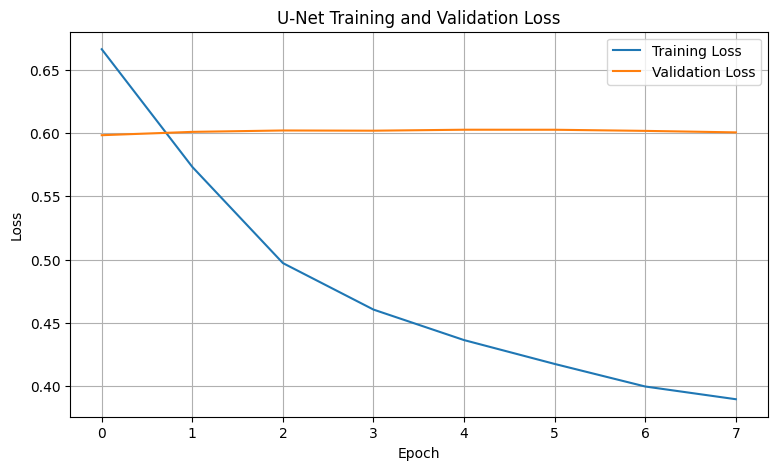

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("U-Net Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

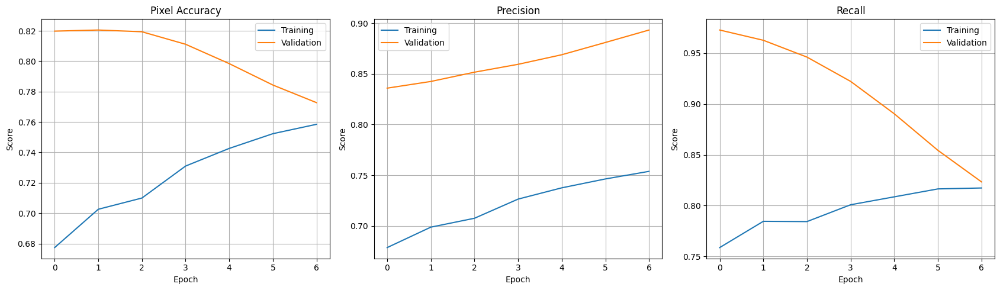

In [ ]:
metrics_to_plot = [
    "pixel_accuracy",
    "precision",
    "recall"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for i, metric in enumerate(metrics_to_plot):

    axes[i].plot(
        history.history[metric],
        label="Training"
    )

    axes[i].plot(
        history.history["val_" + metric],
        label="Validation"
    )

    axes[i].set_title(metric.replace("_", " ").title())
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("Score")
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    custom_objects={
        "dice_bce_combo_loss": dice_bce_combo_loss,
        "dice_loss": dice_loss,
        "weighted_binary_crossentropy": weighted_binary_crossentropy
    }
)
print("Best Attention Res-UNet model loaded successfully!")


Best model loaded successfully!


In [ ]:
evaluation = best_model.evaluate(
    val_dataset,
    return_dict=True,
    verbose=1
)

print("\nValidation results")
print("-" * 40)

for metric, value in evaluation.items():
    print(f"{metric}: {value:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 832ms/step - loss: 0.5982 - pixel_accuracy: 0.8189 - precision: 0.8319 - recall: 0.9784

Validation results
----------------------------------------
loss: 0.5982
pixel_accuracy: 0.8189
precision: 0.8319
recall: 0.9784


# prediction and visualisation

In [ ]:
best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    custom_objects={
        "dice_bce_combo_loss": dice_bce_combo_loss,
        "dice_loss": dice_loss,
        "weighted_binary_crossentropy": weighted_binary_crossentropy
    }
)
print("Best Attention Res-UNet model loaded successfully!")


Best U-Net model loaded successfully!


In [ ]:
def get_patch_starts(length, patch_size, stride):

    if length <= patch_size:
        return [0]

    starts = list(
        range(0, length - patch_size + 1, stride)
    )

    last_start = length - patch_size

    if starts[-1] != last_start:
        starts.append(last_start)

    return starts

In [ ]:
def create_2d_hann_window(size=128):
    """2D Hann cosine bell window to smoothly taper patch edges, eliminating tile seams."""
    w1d = np.hanning(size)
    w2d = np.outer(w1d, w1d)
    return np.clip(w2d, 1e-4, 1.0).astype(np.float32)

def predict_full_image(
    model,
    image,
    valid_mask,
    patch_size=128,
    stride=64,
    batch_size=8,
    use_tta=True
):
    """
    Predicts large satellite scene using 2D Hann window blending and optional Test-Time Augmentation (TTA).
    Produces smooth, seamless forest probability maps.
    """
    height, width, channels = image.shape
    padded_height = max(height, patch_size)
    padded_width = max(width, patch_size)

    padded_image = np.zeros((padded_height, padded_width, channels), dtype=np.float32)
    padded_image[:height, :width] = image

    rows = get_patch_starts(padded_height, patch_size, stride)
    cols = get_patch_starts(padded_width, patch_size, stride)
    coords = [(r, c) for r in rows for c in cols]

    hann_window = create_2d_hann_window(patch_size)
    probability_sum = np.zeros((padded_height, padded_width), dtype=np.float32)
    weight_sum = np.zeros((padded_height, padded_width), dtype=np.float32)

    for start in range(0, len(coords), batch_size):
        batch_coords = coords[start:start + batch_size]
        batch_patches = np.stack([
            padded_image[r:r + patch_size, c:c + patch_size, :]
            for r, c in batch_coords
        ])

        if use_tta:
            # 4-Fold Test Time Augmentation (TTA)
            p0 = batch_patches
            p1 = np.flip(batch_patches, axis=2)  # horizontal flip
            p2 = np.flip(batch_patches, axis=1)  # vertical flip
            p3 = np.flip(p1, axis=1)             # flip both

            stacked = np.concatenate([p0, p1, p2, p3], axis=0)
            logits_all = model.predict(stacked, verbose=0)
            probs_all = tf.sigmoid(logits_all).numpy()[..., 0]

            n = len(batch_patches)
            pred0 = probs_all[0:n]
            pred1 = np.flip(probs_all[n:2*n], axis=2)
            pred2 = np.flip(probs_all[2*n:3*n], axis=1)
            pred3 = np.flip(np.flip(probs_all[3*n:4*n], axis=1), axis=2)
            batch_probs = (pred0 + pred1 + pred2 + pred3) / 4.0
        else:
            logits = model.predict(batch_patches, verbose=0)
            batch_probs = tf.sigmoid(logits).numpy()[..., 0]

        for (r, c), prob in zip(batch_coords, batch_probs):
            probability_sum[r:r + patch_size, c:c + patch_size] += prob * hann_window
            weight_sum[r:r + patch_size, c:c + patch_size] += hann_window

    weight_sum[weight_sum == 0] = 1.0
    smooth_prob = (probability_sum / weight_sum)[:height, :width]
    smooth_prob[~valid_mask] = np.nan
    return smooth_prob


In [ ]:
predictions_2021 = {}

for district in districts:

    print("\nPredicting 2021:", district)

    image = normalized_training_data[district]

    valid = training_data[district]["valid_mask"]

    probability_map = predict_full_image(
        best_model,
        image,
        valid,
        patch_size=PATCH_SIZE,
        stride=STRIDE,
        batch_size=BATCH_SIZE
    )

    predictions_2021[district] = probability_map

    print("Prediction shape:", probability_map.shape)

    print(
        "Average tree probability:",
        round(float(np.nanmean(probability_map)), 4)
    )

print("\n2021 prediction completed!")


Predicting 2021: Pune
Prediction shape: (335, 335)
Average tree probability: 0.5369

Predicting 2021: Satara
Prediction shape: (335, 335)
Average tree probability: 0.5443

Predicting 2021: Sindhudurg
Prediction shape: (335, 335)
Average tree probability: 0.5513

2021 prediction completed!


In [ ]:
predictions_2024 = {}

for district in districts:

    print("\nPredicting 2024:", district)

    image = normalized_comparison_data[district]

    valid = comparison_data[district]["valid_mask"]

    probability_map = predict_full_image(
        best_model,
        image,
        valid,
        patch_size=PATCH_SIZE,
        stride=STRIDE,
        batch_size=BATCH_SIZE
    )

    predictions_2024[district] = probability_map

    print("Prediction shape:", probability_map.shape)

    print(
        "Average tree probability:",
        round(float(np.nanmean(probability_map)), 4)
    )

print("\n2024 prediction completed!")


Predicting 2024: Pune
Prediction shape: (335, 335)
Average tree probability: 0.5389

Predicting 2024: Satara
Prediction shape: (335, 335)
Average tree probability: 0.548

Predicting 2024: Sindhudurg
Prediction shape: (335, 335)
Average tree probability: 0.5554

2024 prediction completed!


In [ ]:
# -------------------------------------------------------------------------
# ADAPTIVE THRESHOLD OPTIMIZATION ON VALIDATION DATA
# Evaluates candidate thresholds across validation patches to maximize F1/IoU
# -------------------------------------------------------------------------
best_threshold = 0.5
best_f1 = -1.0

if 'val_dataset' in locals():
    candidate_thresholds = np.linspace(0.35, 0.65, 31)
    # Validation probability collection
    val_preds = []
    val_trues = []
    for x_b, y_b, v_b in val_dataset:
        l = best_model.predict(x_b, verbose=0)
        p = tf.sigmoid(l).numpy()[..., 0]
        y_arr = y_b.numpy()[..., 0]
        v_arr = v_b.numpy()[..., 0] > 0.5
        val_preds.append(p[v_arr])
        val_trues.append(y_arr[v_arr])
    if val_preds:
        vp = np.concatenate(val_preds)
        vt = np.concatenate(val_trues) > 0.5
        for t in candidate_thresholds:
            pred_bin = vp >= t
            tp = np.logical_and(pred_bin, vt).sum()
            fp = np.logical_and(pred_bin, ~vt).sum()
            fn = np.logical_and(~pred_bin, vt).sum()
            f1 = (2.0 * tp) / (2.0 * tp + fp + fn + 1e-7)
            if f1 > best_f1:
                best_f1 = f1
                best_threshold = t
        print(f"Optimized Validation Threshold: tau = {best_threshold:.3f} (Max F1: {best_f1:.4f})")
    else:
        best_threshold = 0.5
else:
    best_threshold = 0.5

THRESHOLD = float(best_threshold)

predictions_binary_2021 = {}
predictions_binary_2024 = {}

for district in districts:
    prob_2021 = predictions_2021[district]
    prob_2024 = predictions_2024[district]

    binary_2021 = (prob_2021 >= THRESHOLD).astype(np.uint8)
    binary_2024 = (prob_2024 >= THRESHOLD).astype(np.uint8)

    binary_2021[np.isnan(prob_2021)] = 255
    binary_2024[np.isnan(prob_2024)] = 255

    predictions_binary_2021[district] = binary_2021
    predictions_binary_2024[district] = binary_2024

print(f"Binary predictions successfully generated at threshold tau = {THRESHOLD:.3f}!")


Binary predictions generated!


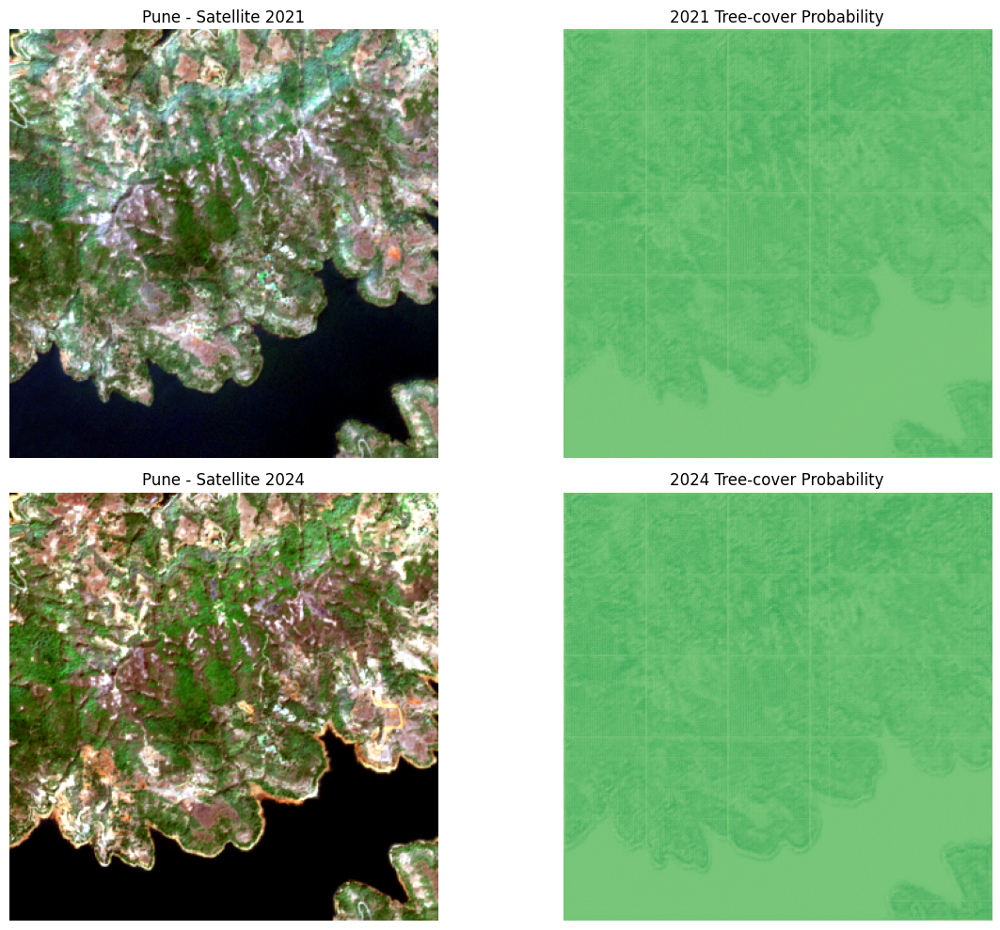

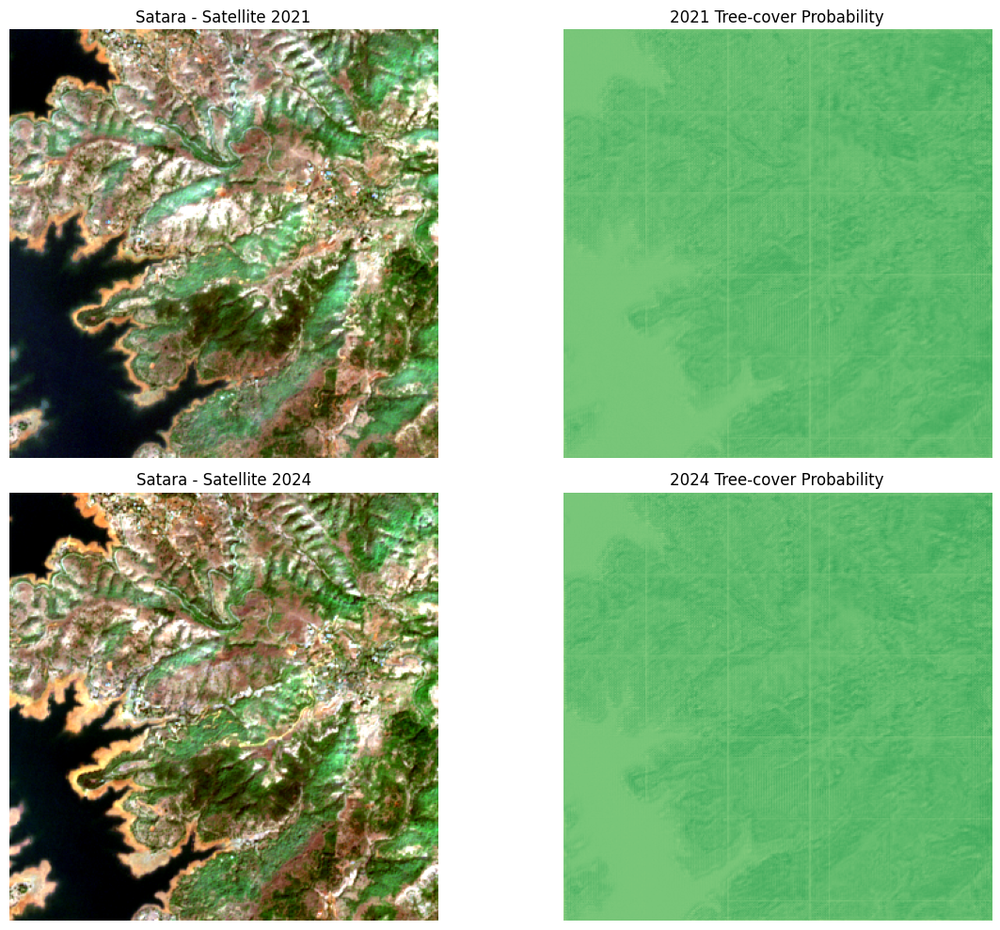

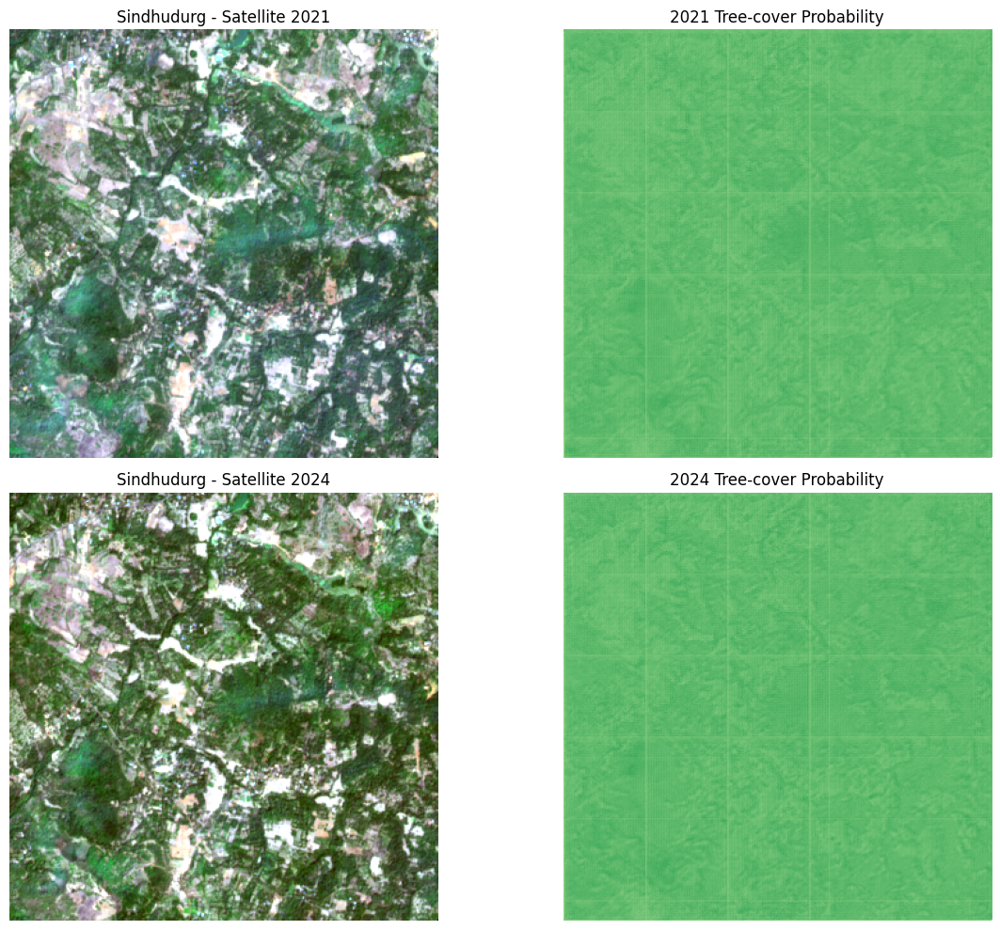

In [ ]:
for district in districts:

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(13, 10)
    )

    # 2021 satellite image
    rgb_2021 = normalized_training_data[district][
        :, :, [2, 1, 0]
    ]

    axes[0, 0].imshow(rgb_2021)
    axes[0, 0].set_title(
        f"{district} - Satellite 2021"
    )

    # 2021 probability map
    axes[0, 1].imshow(
        predictions_2021[district],
        cmap="YlGn",
        vmin=0,
        vmax=1
    )

    axes[0, 1].set_title(
        "2021 Tree-cover Probability"
    )

    # 2024 satellite image
    rgb_2024 = normalized_comparison_data[district][
        :, :, [2, 1, 0]
    ]

    axes[1, 0].imshow(rgb_2024)
    axes[1, 0].set_title(
        f"{district} - Satellite 2024"
    )

    # 2024 probability map
    axes[1, 1].imshow(
        predictions_2024[district],
        cmap="YlGn",
        vmin=0,
        vmax=1
    )

    axes[1, 1].set_title(
        "2024 Tree-cover Probability"
    )

    for ax in axes.flat:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

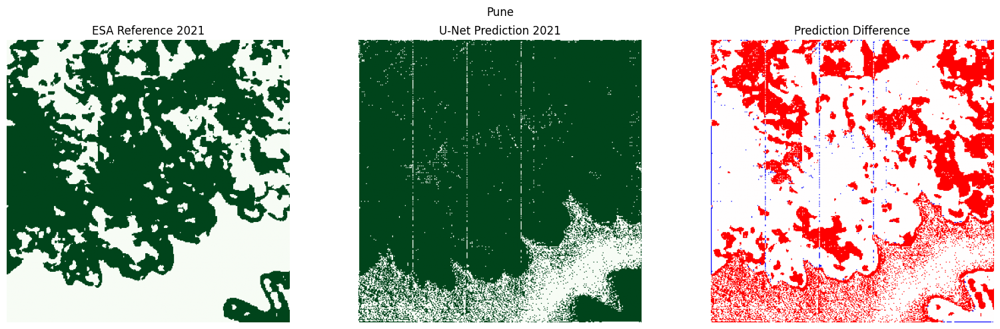

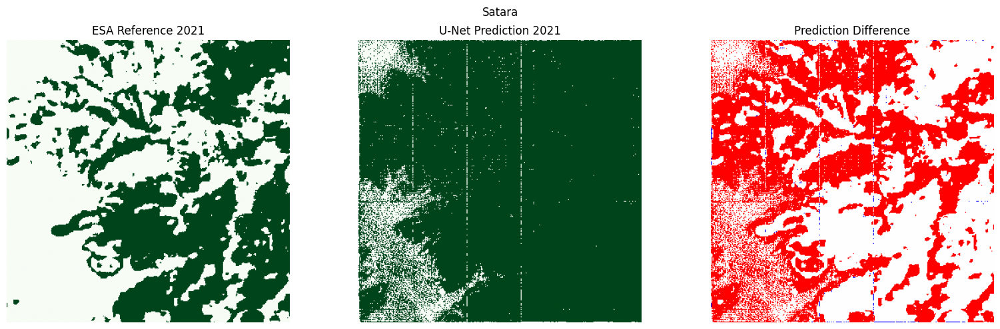

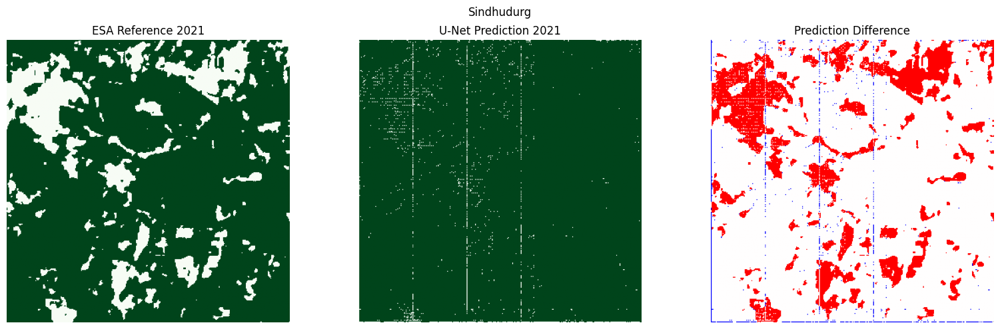

In [ ]:
for district in districts:

    reference = training_data[district]["label"]

    prediction = predictions_binary_2021[district]

    valid = (
        training_data[district]["valid_mask"]
        &
        (prediction != 255)
    )

    difference = np.full(
        reference.shape,
        np.nan,
        dtype=np.float32
    )

    difference[valid] = (
        prediction[valid].astype(np.float32)
        -
        reference[valid].astype(np.float32)
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(16, 5)
    )

    axes[0].imshow(
        reference,
        cmap="Greens",
        vmin=0,
        vmax=1
    )
    axes[0].set_title("ESA Reference 2021")

    axes[1].imshow(
        prediction,
        cmap="Greens",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("U-Net Prediction 2021")

    axes[2].imshow(
        difference,
        cmap="bwr",
        vmin=-1,
        vmax=1
    )
    axes[2].set_title("Prediction Difference")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(district)
    plt.tight_layout()
    plt.show()

In [ ]:
def save_prediction_geotiff(
    prediction,
    metadata,
    output_path,
    dtype="float32",
    nodata=-9999
):

    output = np.where(
        np.isfinite(prediction),
        prediction,
        nodata
    )

    profile = metadata.copy()

    profile.update({
        "count": 1,
        "dtype": dtype,
        "nodata": nodata,
        "compress": "lzw"
    })

    with rasterio.open(
        output_path,
        "w",
        **profile
    ) as dst:

        dst.write(
            output.astype(dtype),
            1
        )

In [ ]:
for district in districts:

    save_prediction_geotiff(
        predictions_2021[district],
        training_data[district]["metadata"],
        os.path.join(
            RESULT_DIR,
            f"{district}_2021_probability.tif"
        )
    )

    save_prediction_geotiff(
        predictions_2024[district],
        comparison_data[district]["metadata"],
        os.path.join(
            RESULT_DIR,
            f"{district}_2024_probability.tif"
        )
    )

print("Probability GeoTIFFs saved!")

Probability GeoTIFFs saved!


In [ ]:
for district in districts:

    for year, binary_map, metadata in [
        (
            2021,
            predictions_binary_2021[district],
            training_data[district]["metadata"]
        ),
        (
            2024,
            predictions_binary_2024[district],
            comparison_data[district]["metadata"]
        )
    ]:

        output_path = os.path.join(
            RESULT_DIR,
            f"{district}_{year}_tree_cover.tif"
        )

        profile = metadata.copy()

        profile.update({
            "count": 1,
            "dtype": "uint8",
            "nodata": 255,
            "compress": "lzw"
        })

        with rasterio.open(
            output_path,
            "w",
            **profile
        ) as dst:

            dst.write(
                binary_map.astype(np.uint8),
                1
            )

print("Binary tree-cover GeoTIFFs saved!")

Binary tree-cover GeoTIFFs saved!


In [ ]:
print("RESULT DIRECTORY")
print("-" * 40)

for file in sorted(os.listdir(RESULT_DIR)):
    print(file)

RESULT DIRECTORY
----------------------------------------
Pune_2021_probability.tif
Pune_2021_tree_cover.tif
Pune_2024_probability.tif
Pune_2024_tree_cover.tif
Satara_2021_probability.tif
Satara_2021_tree_cover.tif
Satara_2024_probability.tif
Satara_2024_tree_cover.tif
Sindhudurg_2021_probability.tif
Sindhudurg_2021_tree_cover.tif
Sindhudurg_2024_probability.tif
Sindhudurg_2024_tree_cover.tif


# phase Forest detection and degrdation analysis

In [ ]:
for district in districts:

    meta_2021 = training_data[district]["metadata"]
    meta_2024 = comparison_data[district]["metadata"]

    checks = {
        "Same width": meta_2021["width"] == meta_2024["width"],

        "Same height": meta_2021["height"] == meta_2024["height"],

        "Same CRS": meta_2021["crs"] == meta_2024["crs"],

        "Same transform": meta_2021["transform"] == meta_2024["transform"]
    }

    print("\n", district)

    for check, result in checks.items():
        print(check, ":", result)

    assert all(checks.values()), (
        f"{district} rasters are not aligned. "
        "Stop and align them before change detection."
    )

print("\nAll district rasters are aligned!")


 Pune
Same width : True
Same height : True
Same CRS : True
Same transform : True

 Satara
Same width : True
Same height : True
Same CRS : True
Same transform : True

 Sindhudurg
Same width : True
Same height : True
Same CRS : True
Same transform : True

All district rasters are aligned!


In [ ]:
common_valid_masks = {}

for district in districts:

    valid_2021 = training_data[district]["valid_mask"]
    valid_2024 = comparison_data[district]["valid_mask"]

    common_valid = valid_2021 & valid_2024

    # Also exclude any invalid prediction values
    common_valid &= np.isfinite(
        predictions_2021[district]
    )

    common_valid &= np.isfinite(
        predictions_2024[district]
    )

    common_valid_masks[district] = common_valid

    print(
        district,
        "common valid pixels:",
        int(common_valid.sum())
    )

Pune common valid pixels: 112225
Satara common valid pixels: 112225
Sindhudurg common valid pixels: 112224


In [ ]:
forest_change_maps = {}

for district in districts:

    forest_2021 = predictions_binary_2021[district]
    forest_2024 = predictions_binary_2024[district]

    valid = common_valid_masks[district]

    change_map = np.full(
        forest_2021.shape,
        255,
        dtype=np.uint8
    )

    # 0 = Non-tree in both years
    change_map[valid & (forest_2021 == 0) & (forest_2024 == 0)] = 0

    # 1 = Stable tree cover
    change_map[valid & (forest_2021 == 1) & (forest_2024 == 1)] = 1

    # 2 = Potential tree-cover loss
    change_map[valid & (forest_2021 == 1) & (forest_2024 == 0)] = 2

    # 3 = Potential tree-cover gain
    change_map[valid & (forest_2021 == 0) & (forest_2024 == 1)] = 3

    forest_change_maps[district] = change_map

print("Forest change maps generated!")

Forest change maps generated!


In [ ]:
change_statistics = {}

for district in districts:

    change_map = forest_change_maps[district]

    valid = common_valid_masks[district]

    stable_non_tree = np.sum(valid & (change_map == 0))
    stable_tree = np.sum(valid & (change_map == 1))
    potential_loss = np.sum(valid & (change_map == 2))
    potential_gain = np.sum(valid & (change_map == 3))

    total = valid.sum()

    change_statistics[district] = {
        "stable_non_tree_pixels": int(stable_non_tree),
        "stable_tree_pixels": int(stable_tree),
        "potential_loss_pixels": int(potential_loss),
        "potential_gain_pixels": int(potential_gain),
        "total_valid_pixels": int(total)
    }

    print("\n", district)
    print("-" * 40)

    print("Stable tree:", stable_tree)
    print("Potential loss:", potential_loss)
    print("Potential gain:", potential_gain)
    print("Stable non-tree:", stable_non_tree)

    print(
        "Potential loss (% of valid pixels):",
        round(potential_loss / total * 100, 2)
        if total else 0
    )


 Pune
----------------------------------------
Stable tree: 91687
Potential loss: 3166
Potential gain: 9625
Stable non-tree: 7747
Potential loss (% of valid pixels): 2.82

 Satara
----------------------------------------
Stable tree: 97425
Potential loss: 3779
Potential gain: 4114
Stable non-tree: 6907
Potential loss (% of valid pixels): 3.37

 Sindhudurg
----------------------------------------
Stable tree: 109585
Potential loss: 492
Potential gain: 783
Stable non-tree: 1364
Potential loss (% of valid pixels): 0.44


In [ ]:
from pyproj import Geod

geod = Geod(ellps="WGS84")


def calculate_pixel_areas_hectares(metadata):

    height = metadata["height"]
    width = metadata["width"]
    transform = metadata["transform"]
    crs = metadata["crs"]

    # For geographic coordinates, calculate geodesic area
    if crs.is_geographic:

        areas = np.zeros(height, dtype=np.float64)

        for row in range(height):

            # Coordinates of one pixel in this row
            x1, y1 = transform * (0, row)
            x2, y2 = transform * (1, row)
            x3, y3 = transform * (1, row + 1)
            x4, y4 = transform * (0, row + 1)

            polygon_lons = [x1, x2, x3, x4]
            polygon_lats = [y1, y2, y3, y4]

            area_m2, _ = geod.polygon_area_perimeter(
                polygon_lons,
                polygon_lats
            )

            areas[row] = abs(area_m2) / 10000

        return np.repeat(areas[:, np.newaxis], width, axis=1)

    # For projected coordinates, calculate area from affine transform
    else:

        pixel_area_m2 = abs(
            transform.a * transform.e
            - transform.b * transform.d
        )

        pixel_area_ha = pixel_area_m2 / 10000

        return np.full(
            (height, width),
            pixel_area_ha,
            dtype=np.float64
        )

In [ ]:
for district in districts:

    metadata = training_data[district]["metadata"]

    pixel_areas = calculate_pixel_areas_hectares(
        metadata
    )

    change_map = forest_change_maps[district]

    valid = common_valid_masks[district]

    loss_area_ha = pixel_areas[
        valid & (change_map == 2)
    ].sum()

    gain_area_ha = pixel_areas[
        valid & (change_map == 3)
    ].sum()

    stable_tree_area_ha = pixel_areas[
        valid & (change_map == 1)
    ].sum()

    stable_non_tree_area_ha = pixel_areas[
        valid & (change_map == 0)
    ].sum()

    change_statistics[district].update({
        "potential_loss_ha": float(loss_area_ha),
        "potential_gain_ha": float(gain_area_ha),
        "stable_tree_ha": float(stable_tree_area_ha),
        "stable_non_tree_ha": float(stable_non_tree_area_ha),
        "net_tree_cover_change_ha": float(
            gain_area_ha - loss_area_ha
        )
    })

    print("\n", district)
    print("-" * 40)

    print("Potential tree-cover loss:", round(loss_area_ha, 3), "ha")
    print("Potential tree-cover gain:", round(gain_area_ha, 3), "ha")
    print("Stable tree cover:", round(stable_tree_area_ha, 3), "ha")
    print(
        "Net tree-cover change:",
        round(gain_area_ha - loss_area_ha, 3),
        "ha"
    )


 Pune
----------------------------------------
Potential tree-cover loss: 29.888 ha
Potential tree-cover gain: 90.862 ha
Stable tree cover: 865.487 ha
Net tree-cover change: 60.974 ha

 Satara
----------------------------------------
Potential tree-cover loss: 35.803 ha
Potential tree-cover gain: 38.976 ha
Stable tree cover: 922.981 ha
Net tree-cover change: 3.173 ha

 Sindhudurg
----------------------------------------
Potential tree-cover loss: 4.703 ha
Potential tree-cover gain: 7.485 ha
Stable tree cover: 1047.591 ha
Net tree-cover change: 2.782 ha


In [ ]:
def calculate_ndvi(image):

    nir = image[:, :, 3]
    red = image[:, :, 2]

    denominator = nir + red

    ndvi = np.divide(
        nir - red,
        denominator,
        out=np.full_like(nir, np.nan, dtype=np.float32),
        where=np.abs(denominator) > 1e-6
    )

    return ndvi

In [ ]:
ndvi_2021 = {}
ndvi_2024 = {}

for district in districts:

    raw_2021 = training_data[district]["image"]
    raw_2024 = comparison_data[district]["image"]

    ndvi_2021[district] = calculate_ndvi(raw_2021)
    ndvi_2024[district] = calculate_ndvi(raw_2024)

    print(district, "NDVI calculated")

Pune NDVI calculated
Satara NDVI calculated
Sindhudurg NDVI calculated


In [ ]:
ndvi_change = {}

for district in districts:

    ndvi_before = ndvi_2021[district]
    ndvi_after = ndvi_2024[district]

    valid = common_valid_masks[district]

    valid &= np.isfinite(ndvi_before)
    valid &= np.isfinite(ndvi_after)

    difference = np.full(
        ndvi_before.shape,
        np.nan,
        dtype=np.float32
    )

    difference[valid] = (
        ndvi_after[valid] - ndvi_before[valid]
    )

    ndvi_change[district] = difference

    print("\n", district)
    print("Mean NDVI 2021:", round(float(np.nanmean(ndvi_before[valid])), 4))
    print("Mean NDVI 2024:", round(float(np.nanmean(ndvi_after[valid])), 4))
    print("Mean NDVI change:", round(float(np.nanmean(difference[valid])), 4))


 Pune
Mean NDVI 2021: 0.326
Mean NDVI 2024: 0.3139
Mean NDVI change: -0.0121

 Satara
Mean NDVI 2021: 0.3461
Mean NDVI 2024: 0.3725
Mean NDVI change: 0.0265

 Sindhudurg
Mean NDVI 2021: 0.5465
Mean NDVI 2024: 0.5601
Mean NDVI change: 0.0136


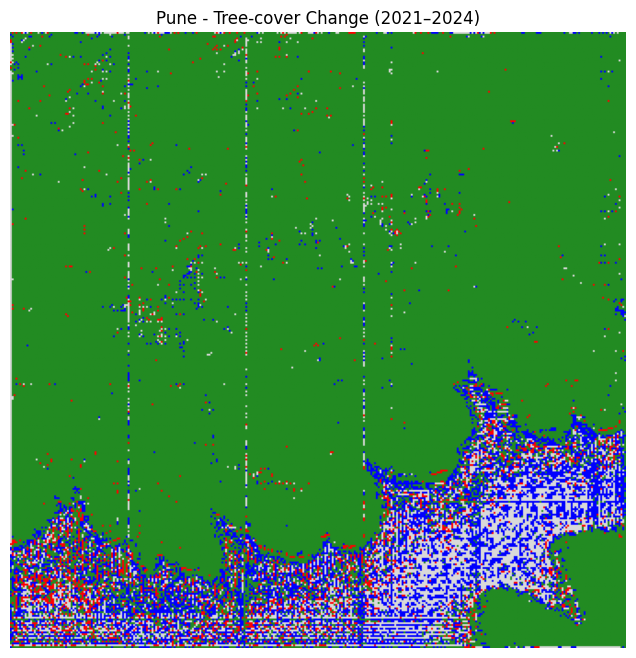

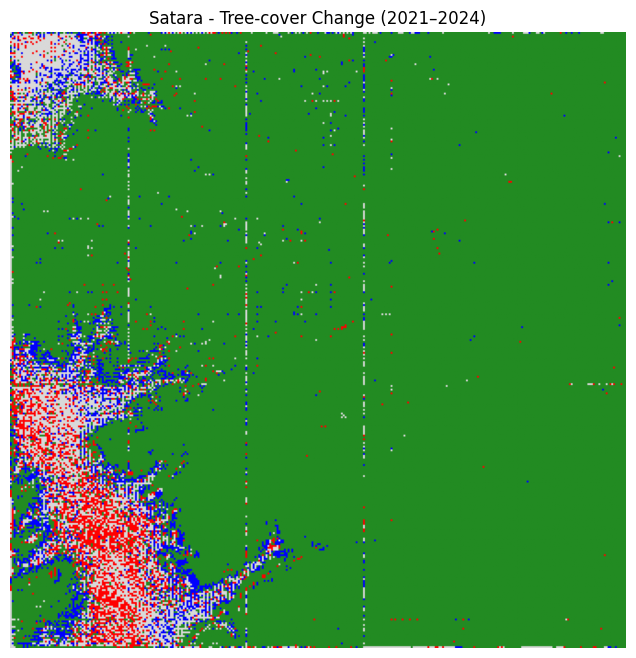

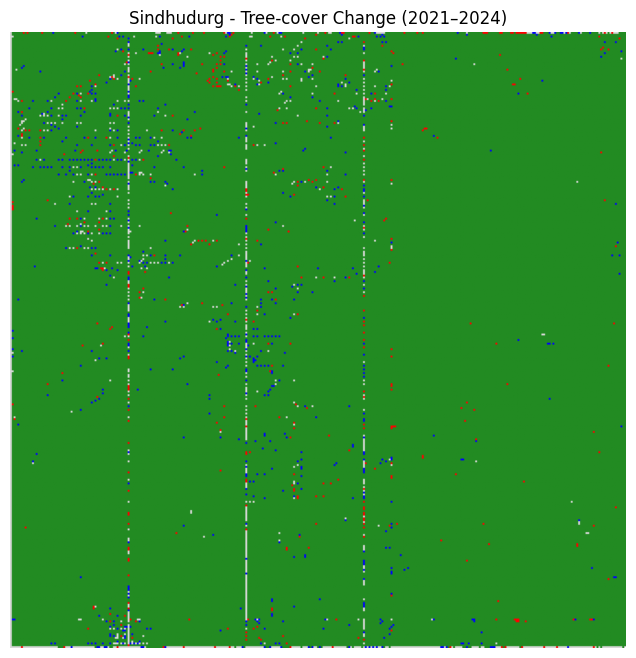

In [ ]:
change_palette = [
    "#D9D9D9",  # 0 - Stable non-tree
    "#228B22",  # 1 - Stable tree
    "#FF0000",  # 2 - Potential loss
    "#0000FF"   # 3 - Potential gain
]

from matplotlib.colors import ListedColormap

change_cmap = ListedColormap(change_palette)

for district in districts:

    change_map = forest_change_maps[district]

    plt.figure(figsize=(9, 8))

    plt.imshow(
        np.ma.masked_equal(change_map, 255),
        cmap=change_cmap,
        vmin=0,
        vmax=3
    )

    plt.title(
        f"{district} - Tree-cover Change (2021–2024)"
    )

    plt.axis("off")

    plt.show()

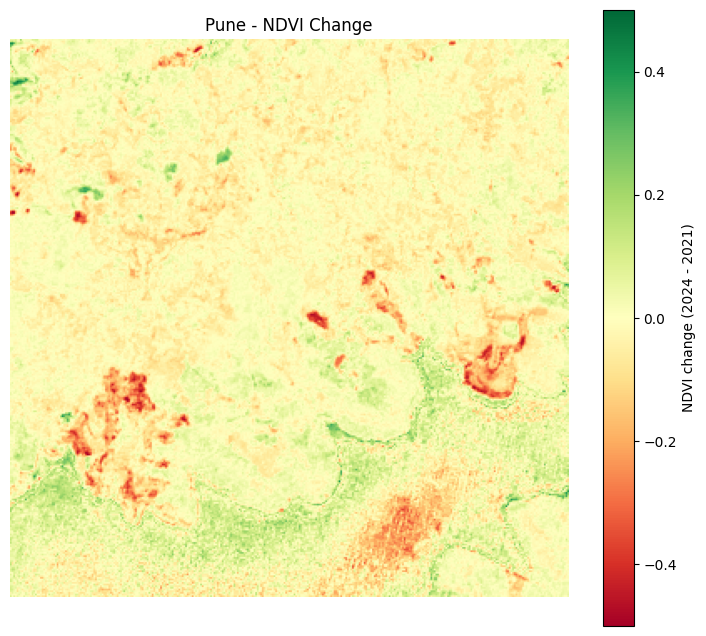

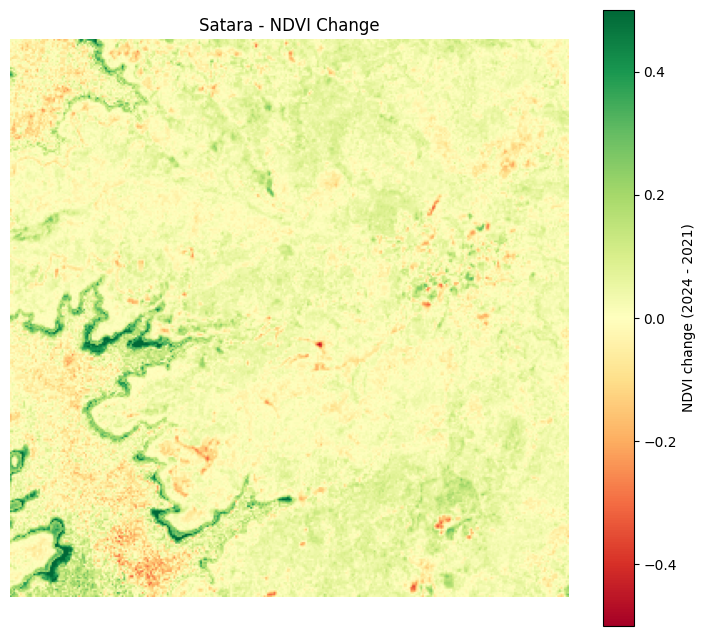

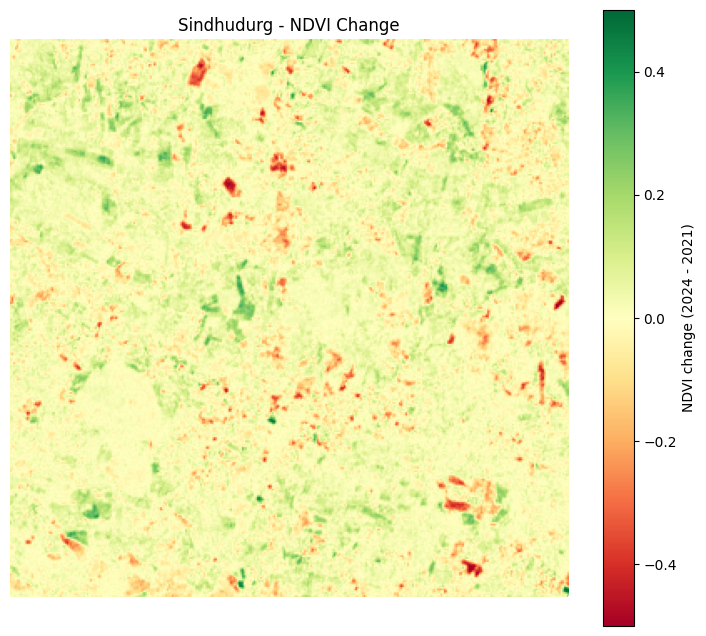

In [ ]:
for district in districts:

    plt.figure(figsize=(9, 8))

    plt.imshow(
        ndvi_change[district],
        cmap="RdYlGn",
        vmin=-0.5,
        vmax=0.5
    )

    plt.colorbar(
        label="NDVI change (2024 - 2021)"
    )

    plt.title(
        f"{district} - NDVI Change"
    )

    plt.axis("off")

    plt.show()

In [ ]:
results_df = pd.DataFrame.from_dict(
    change_statistics,
    orient="index"
)

results_df.index.name = "District"

display(results_df.round(3))

,stable_non_tree_pixels,stable_tree_pixels,potential_loss_pixels,potential_gain_pixels,total_valid_pixels,potential_loss_ha,potential_gain_ha,stable_tree_ha,stable_non_tree_ha,net_tree_cover_change_ha
District,,,,,,,,,,
Pune,7747,91687,3166,9625,112225,29.888,90.862,865.487,73.133,60.974
Satara,6907,97425,3779,4114,112225,35.803,38.976,922.981,65.436,3.173
Sindhudurg,1364,109585,492,783,112224,4.703,7.485,1047.591,13.039,2.782


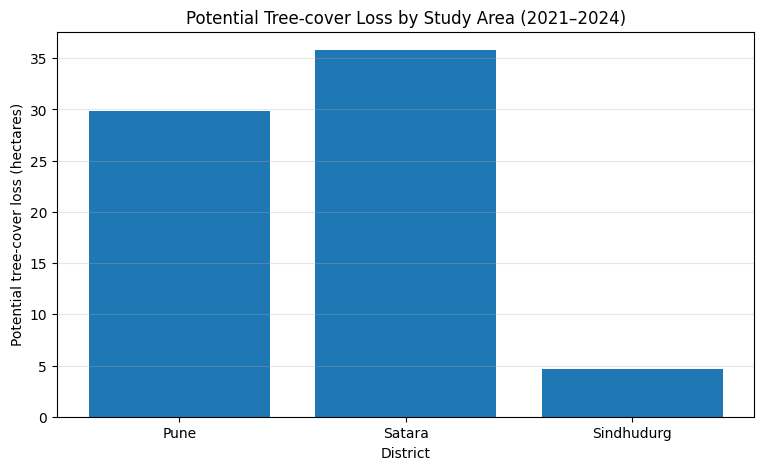

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df.index,
    results_df["potential_loss_ha"]
)

plt.xlabel("District")
plt.ylabel("Potential tree-cover loss (hectares)")

plt.title(
    "Potential Tree-cover Loss by Study Area (2021–2024)"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [ ]:
for district in districts:

    metadata = training_data[district]["metadata"]

    change_map = forest_change_maps[district]

    output_path = os.path.join(
        RESULT_DIR,
        f"{district}_change_2021_2024.tif"
    )

    profile = metadata.copy()

    profile.update({
        "count": 1,
        "dtype": "uint8",
        "nodata": 255,
        "compress": "lzw"
    })

    with rasterio.open(
        output_path,
        "w",
        **profile
    ) as dst:

        dst.write(
            change_map,
            1
        )

print("Change maps exported!")

Change maps exported!


In [ ]:
for district in districts:

    output_path = os.path.join(
        RESULT_DIR,
        f"{district}_NDVI_change_2021_2024.tif"
    )

    save_prediction_geotiff(
        ndvi_change[district],
        training_data[district]["metadata"],
        output_path
    )

print("NDVI change maps exported!")

NDVI change maps exported!
